In [41]:
import os 
import sys 
from pathlib import Path 

import numpy as np 
import torch 
import torch .nn .functional as F 
import matplotlib .pyplot as plt 
import umap 


project_root =Path .cwd ().parent 
sys .path .insert (0 ,str (project_root ))

from src .models .main .classical import ShallowCNN ,ClassicalModel 
from src .models .main .models import QuantumModel ,ExtentedQuantumModel 
from src .models .fusion import OnlineFusionModel 
from src .utils .dataloader import BreastMNISTLoader ,INbreastLoader ,BUSUCLMLoader 

In [42]:




EXPERIMENT_CONFIG ={
"dataset":"BreastMNIST",
"classical_model_type":"shallow",
"quantum_model_type":"extended_quantum",
"batch_size":32 ,
"image_size":28 ,
"num_classes":2 ,
"feature_dim":128 ,
"n_qubits":4 ,
"n_layers":1 ,
"patch_size":2 ,
"output_dir":"../../experiments/models/fusion/online/BreastMNIST/shallow_extended_quantum/umap",
}


FUSION_CHECKPOINT_PATH =os .path .join (
EXPERIMENT_CONFIG ["output_dir"],
f"best_fusion_{EXPERIMENT_CONFIG ['classical_model_type']}_{EXPERIMENT_CONFIG ['quantum_model_type']}.pth"
)
CLASSICAL_PRETRAINED_PATH ="../../experiments/models/classical/BreastMNIST/shallow/best_shallow.pth"
QUANTUM_PRETRAINED_PATH ="../../experiments/models/quantum/trainable/BreastMNIST/checkpoints/model_epoch15.pth"

DATASET =EXPERIMENT_CONFIG ["dataset"]
CLASSICAL_MODEL_TYPE =EXPERIMENT_CONFIG ["classical_model_type"]
QUANTUM_MODEL_TYPE =EXPERIMENT_CONFIG ["quantum_model_type"]
BATCH_SIZE =EXPERIMENT_CONFIG ["batch_size"]
IMAGE_SIZE =EXPERIMENT_CONFIG ["image_size"]
NUM_CLASSES =EXPERIMENT_CONFIG ["num_classes"]
FEATURE_DIM =EXPERIMENT_CONFIG ["feature_dim"]
N_QUBITS =EXPERIMENT_CONFIG ["n_qubits"]
N_LAYERS =EXPERIMENT_CONFIG ["n_layers"]
PATCH_SIZE =EXPERIMENT_CONFIG ["patch_size"]
OUTPUT_DIR =EXPERIMENT_CONFIG ["output_dir"]

os .makedirs (OUTPUT_DIR ,exist_ok =True )
device =torch .device ("cuda"if torch .cuda .is_available ()else "cpu")

print ("Configuracao ativa:")
for k ,v in EXPERIMENT_CONFIG .items ():
    print (f"  - {k }: {v }")
print ("Fusion checkpoint:",FUSION_CHECKPOINT_PATH )
print ("Output dir:",OUTPUT_DIR )
print ("Device:",device )

Configuracao ativa:
  - dataset: BreastMNIST
  - classical_model_type: shallow
  - quantum_model_type: extended_quantum
  - batch_size: 32
  - image_size: 28
  - num_classes: 2
  - feature_dim: 128
  - n_qubits: 4
  - n_layers: 1
  - patch_size: 2
  - output_dir: ../../experiments/models/fusion/online/BreastMNIST/shallow_extended_quantum/umap
Fusion checkpoint: ../../experiments/models/fusion/online/BreastMNIST/shallow_extended_quantum/umap/best_fusion_shallow_extended_quantum.pth
Output dir: ../../experiments/models/fusion/online/BreastMNIST/shallow_extended_quantum/umap
Device: cuda


In [43]:
if DATASET =="BreastMNIST":
    loader =BreastMNISTLoader (batch_size =BATCH_SIZE ,image_size =IMAGE_SIZE )
elif DATASET =="INbreast":
    loader =INbreastLoader (batch_size =BATCH_SIZE ,image_size =IMAGE_SIZE )
elif DATASET =="BUSUCLM":
    loader =BUSUCLMLoader (batch_size =BATCH_SIZE ,image_size =IMAGE_SIZE )
else :
    raise ValueError (f"Dataset nao suportado: {DATASET }")

train_loader ,test_loader ,val_loader =loader .get_dataloaders ()
print (f"✓ Dataset {DATASET } carregado (test batches: {len (test_loader )})")

if CLASSICAL_MODEL_TYPE =="shallow":
    classical_model =ShallowCNN (num_classes =NUM_CLASSES ,input_channels =1 )
elif CLASSICAL_MODEL_TYPE =="resnet":
    classical_model =ClassicalModel (num_classes =NUM_CLASSES )
else :
    raise ValueError (f"Tipo de modelo classico nao suportado: {CLASSICAL_MODEL_TYPE }")

if QUANTUM_MODEL_TYPE =="quantum":
    rand_params =np .random .uniform (high =2 *np .pi ,size =(N_LAYERS ,N_QUBITS ))
    quantum_model =QuantumModel (
    n_qubits =N_QUBITS ,
    n_layers =N_LAYERS ,
    rand_params =rand_params ,
    output_size =(14 ,14 ),
    patch_size =PATCH_SIZE ,
    num_classes =NUM_CLASSES 
    )
elif QUANTUM_MODEL_TYPE =="extended_quantum":
    quantum_model =ExtentedQuantumModel (
    n_qubits =N_QUBITS ,
    n_layers =N_LAYERS ,
    num_classes =NUM_CLASSES ,
    patch_size =PATCH_SIZE ,
    mode ="2d",
    stride =PATCH_SIZE ,
    use_parallel =True 
    )
else :
    raise ValueError (f"Tipo de modelo quantico nao suportado: {QUANTUM_MODEL_TYPE }")

fusion_model =OnlineFusionModel (
classical_model =classical_model ,
quantum_model =quantum_model ,
feature_dim =FEATURE_DIM ,
num_classes =NUM_CLASSES ,
freeze_classical =False ,
freeze_quantum =False 
).to (device )

fusion_model .eval ()
with torch .no_grad ():
    dummy_input =torch .randn (1 ,1 ,IMAGE_SIZE ,IMAGE_SIZE ).to (device )
    _ =fusion_model (dummy_input )
fusion_model .train ()

if os .path .exists (FUSION_CHECKPOINT_PATH ):
    fusion_model .load_state_dict (torch .load (FUSION_CHECKPOINT_PATH ,map_location =device ))
    print (f"✓ Fusion checkpoint carregado: {FUSION_CHECKPOINT_PATH }")
elif CLASSICAL_PRETRAINED_PATH or QUANTUM_PRETRAINED_PATH :
    fusion_model .load_pretrained_weights (
    classical_path =CLASSICAL_PRETRAINED_PATH ,
    quantum_path =QUANTUM_PRETRAINED_PATH ,
    device =device 
    )
    print ("✓ Pesos base carregados (classico/quantico)")
else :
    print ("⚠ Nenhum checkpoint encontrado. Usando pesos aleatorios.")

fusion_model .eval ()

Using downloaded and verified file: /home/eflammere/.medmnist/breastmnist.npz
Using downloaded and verified file: /home/eflammere/.medmnist/breastmnist.npz
Using downloaded and verified file: /home/eflammere/.medmnist/breastmnist.npz
✓ Dataset BreastMNIST carregado (test batches: 5)
Quantum layer has 4 trainable parameters
Requires grad: True
✓ Loaded classical model weights from ../../experiments/models/classical/BreastMNIST/shallow/best_shallow.pth
✓ Loaded quantum model weights from ../../experiments/models/quantum/trainable/BreastMNIST/checkpoints/model_epoch15.pth
✓ Pesos base carregados (classico/quantico)


/home/eflammere/HybridEmbeddingsForBreastCancerDetection/src/models/fusion.py:218: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(classical_path, map_

OnlineFusionModel(
  (classical_model): ShallowCNN(
    (conv1): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (conv2): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (conv3): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): AdaptiveAvgPool2d(output_size=(1, 1))
    )
    (fc): Linear(in_features=128, out_f

L2 Classical: (156, 128)
L2 Quantum: (156, 128)
L2 Fusion: (156, 256)
Labels: (156,)

[ANTES] Classical L2
  media: 0.003083
  min:   -0.320289
  max:   0.310237
  escala (10^k): 1.000000

[DEPOIS] Classical L2
  media: 0.323372
  min:   0.000000
  max:   0.630526

[ANTES] Quantum L2
  media: -0.013031
  min:   -0.309774
  max:   0.284374
  escala (10^k): 1.000000

[DEPOIS] Quantum L2
  media: 0.296742
  min:   0.000000
  max:   0.594148

[ANTES] Fusion L2
  media: -0.004974
  min:   -0.320289
  max:   0.310237
  escala (10^k): 1.000000

[DEPOIS] Fusion L2
  media: 0.315314
  min:   0.000000
  max:   0.630526


/home/eflammere/miniconda3/envs/quantumEnvironment/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


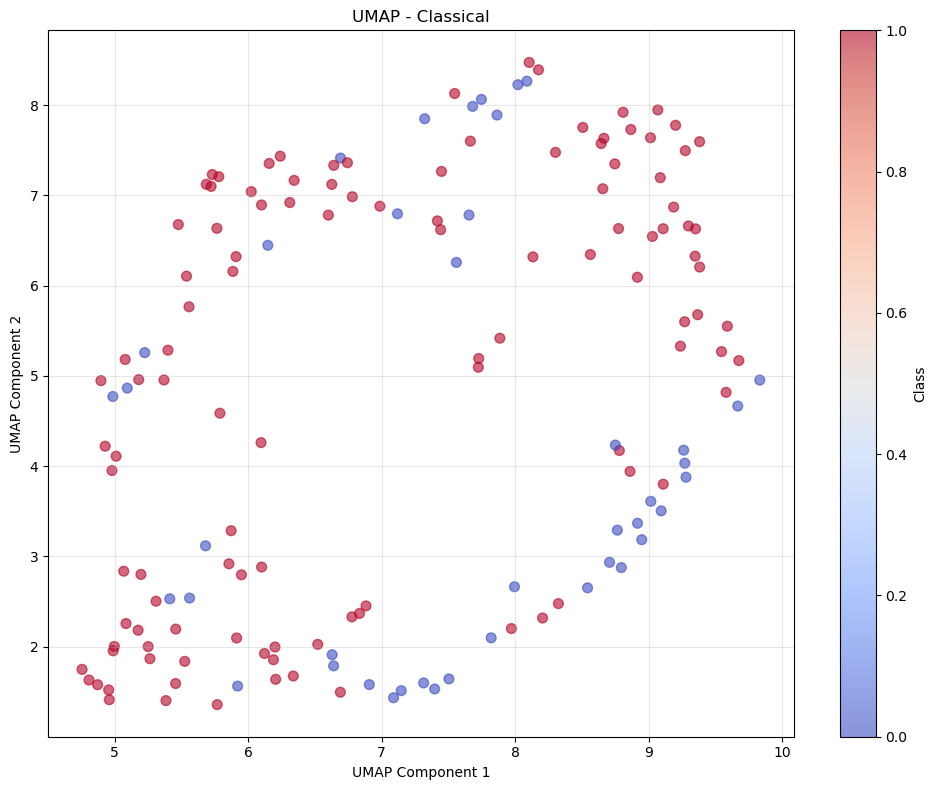

Saved: ../../experiments/models/fusion/online/BreastMNIST/shallow_extended_quantum/umap/umap_classical.png


/home/eflammere/miniconda3/envs/quantumEnvironment/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


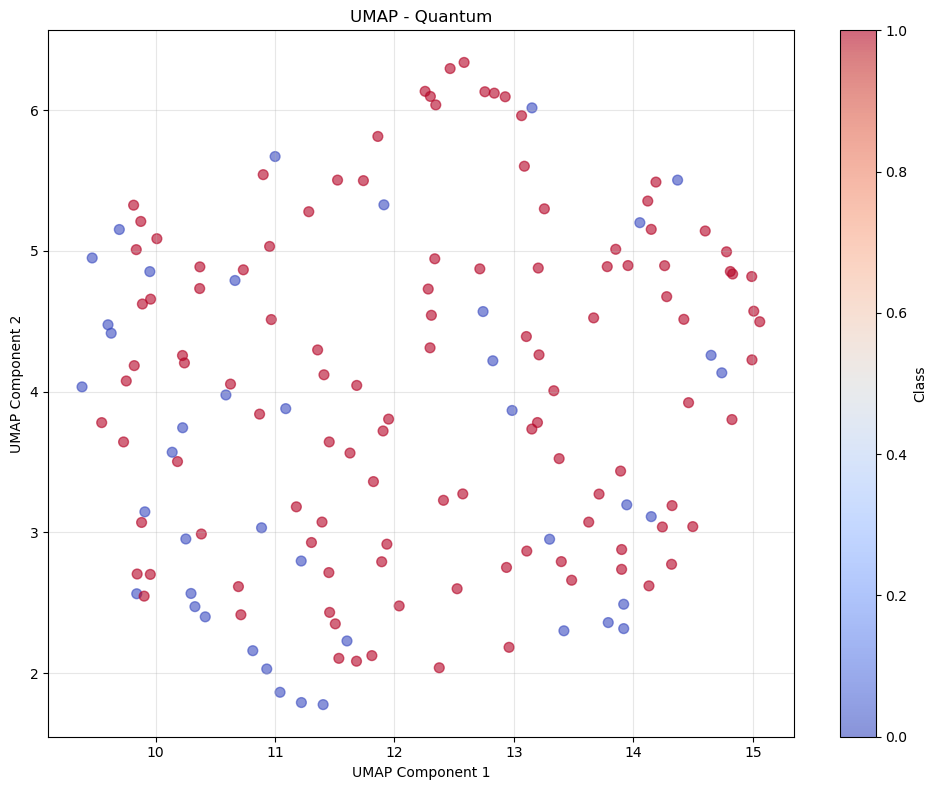

Saved: ../../experiments/models/fusion/online/BreastMNIST/shallow_extended_quantum/umap/umap_quantum.png


/home/eflammere/miniconda3/envs/quantumEnvironment/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


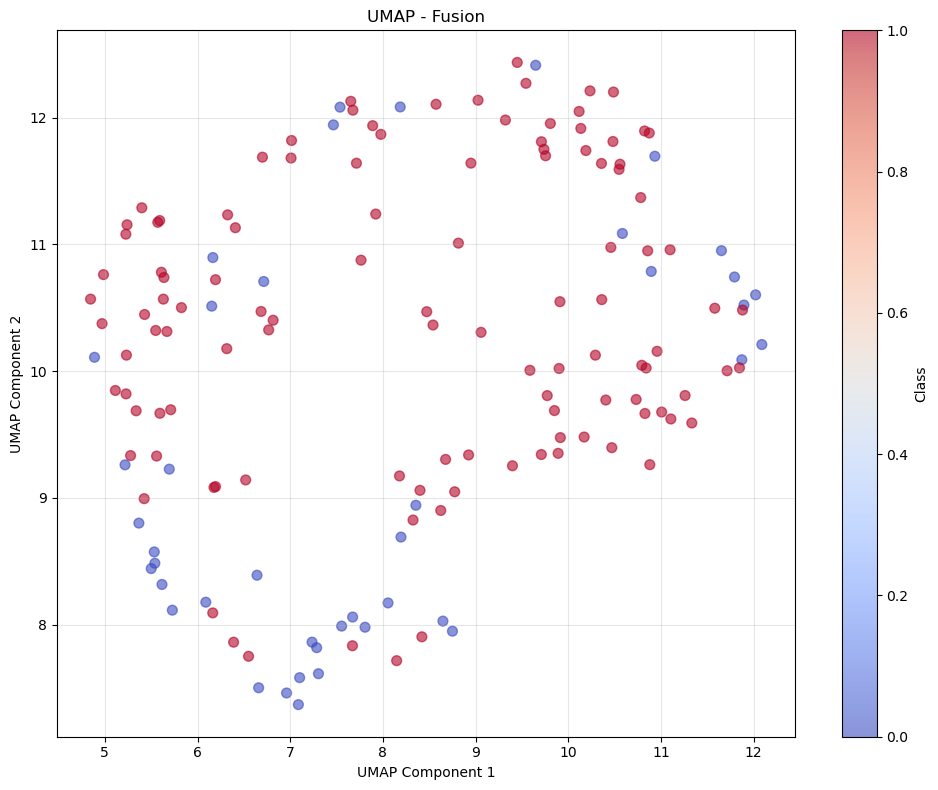

Saved: ../../experiments/models/fusion/online/BreastMNIST/shallow_extended_quantum/umap/umap_fusion.png


/home/eflammere/miniconda3/envs/quantumEnvironment/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


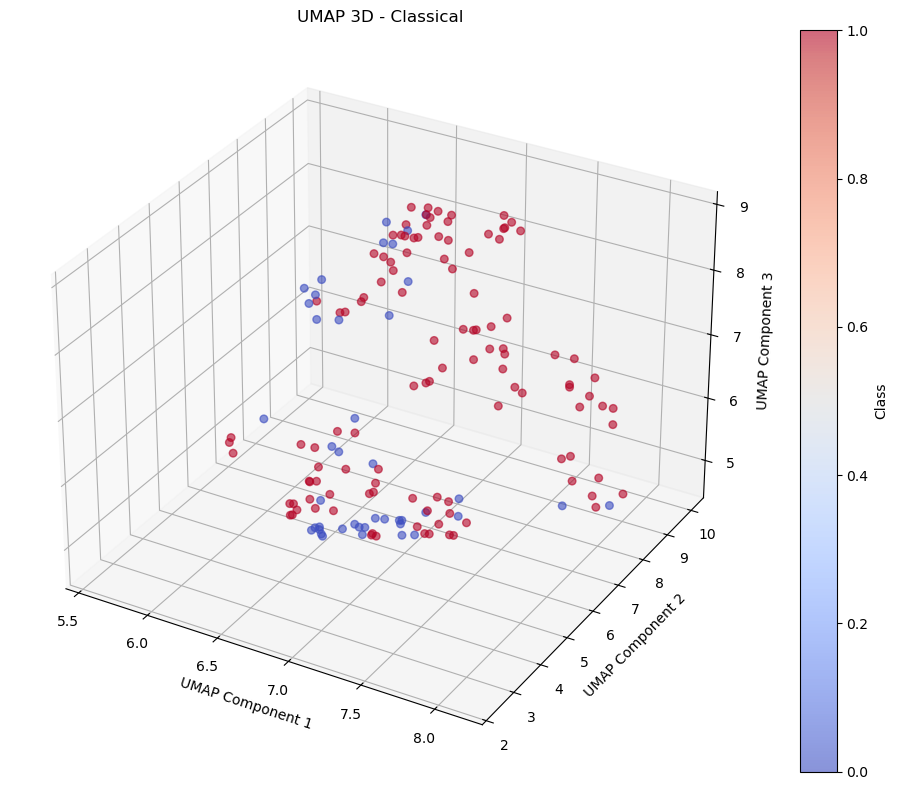

Saved: ../../experiments/models/fusion/online/BreastMNIST/shallow_extended_quantum/umap/umap_3d_classical.png


/home/eflammere/miniconda3/envs/quantumEnvironment/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


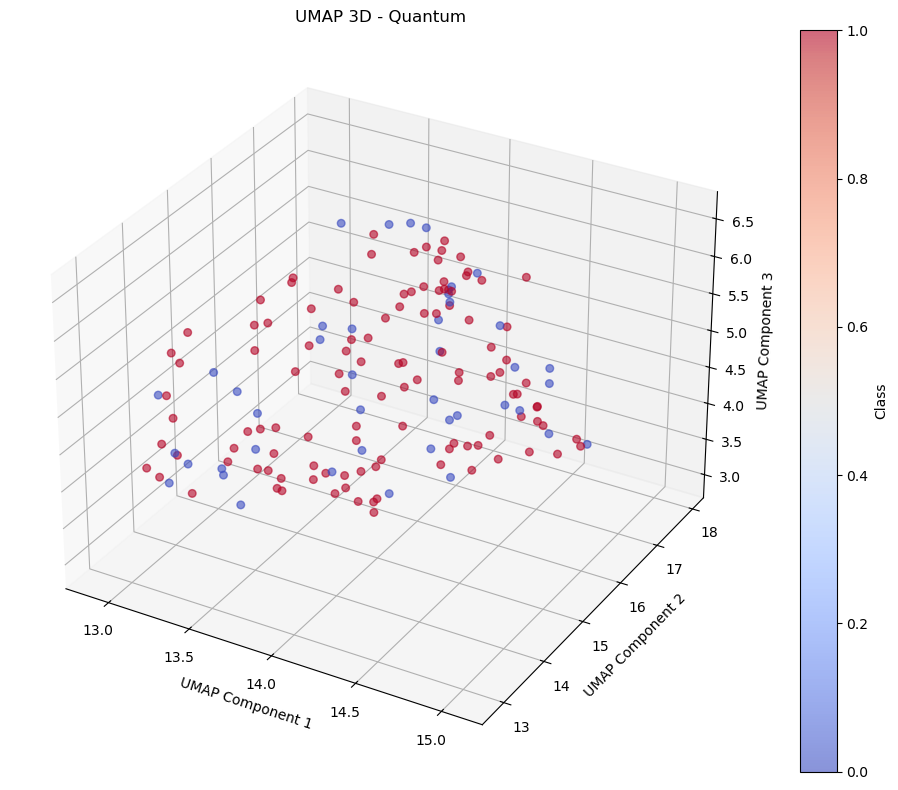

Saved: ../../experiments/models/fusion/online/BreastMNIST/shallow_extended_quantum/umap/umap_3d_quantum.png


/home/eflammere/miniconda3/envs/quantumEnvironment/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


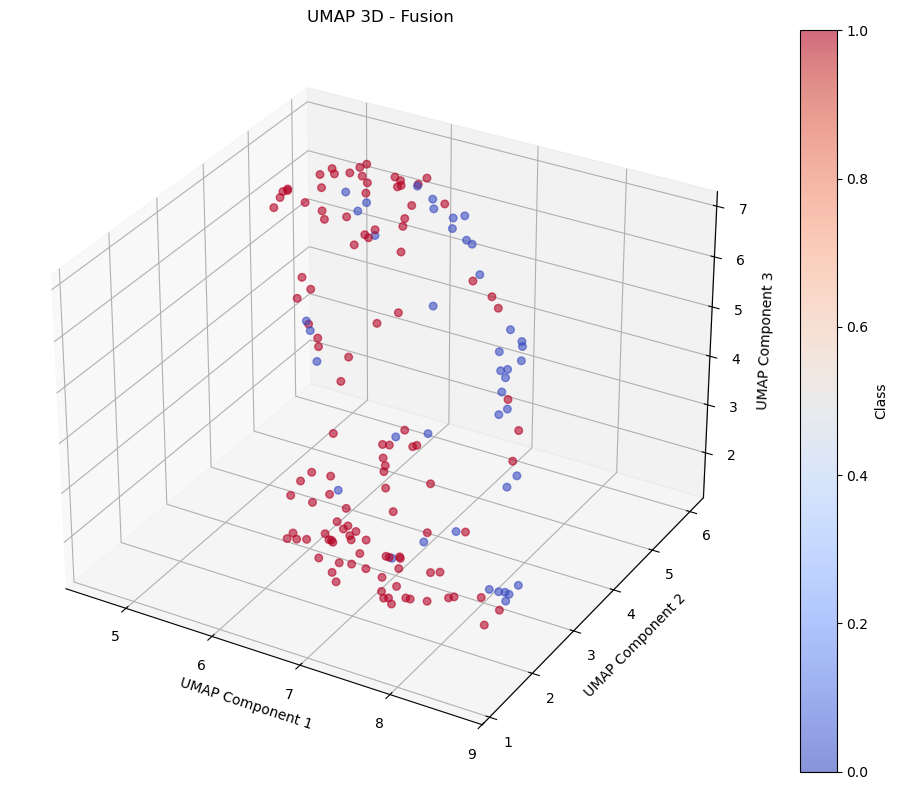

Saved: ../../experiments/models/fusion/online/BreastMNIST/shallow_extended_quantum/umap/umap_3d_fusion.png


In [44]:
MAX_SAMPLES =None 

def _flatten (feats ):
    if feats .ndim >2 :
        return feats .flatten (start_dim =1 )
    return feats 

classical_l2_list =[]
quantum_l2_list =[]
fusion_l2_list =[]
sample_labels =[]

with torch .no_grad ():
    for images ,labels in test_loader :
        images =images .to (device )

        classical_raw =fusion_model .classical_model .extract_features (images )
        quantum_raw =fusion_model .quantum_model .extract_features (images )

        classical_raw =_flatten (classical_raw )
        quantum_raw =_flatten (quantum_raw )

        if fusion_model .classical_projection is None or fusion_model .quantum_projection is None :
            fusion_model ._init_projections (classical_raw .shape [1 ],quantum_raw .shape [1 ],images .device )

        classical_proj =fusion_model .classical_projection (classical_raw )
        quantum_proj =fusion_model .quantum_projection (quantum_raw )


        classical_l2 =F .normalize (classical_proj ,p =2 ,dim =1 )
        quantum_l2 =F .normalize (quantum_proj ,p =2 ,dim =1 )
        fusion_l2 =torch .cat ([classical_l2 ,quantum_l2 ],dim =1 )

        classical_l2_list .append (classical_l2 .cpu ().numpy ())
        quantum_l2_list .append (quantum_l2 .cpu ().numpy ())
        fusion_l2_list .append (fusion_l2 .cpu ().numpy ())
        sample_labels .append (labels .numpy ())

classical_l2 =np .concatenate (classical_l2_list ,axis =0 )
quantum_l2 =np .concatenate (quantum_l2_list ,axis =0 )
fusion_l2 =np .concatenate (fusion_l2_list ,axis =0 )
sample_labels =np .concatenate (sample_labels ,axis =0 ).squeeze ()

if MAX_SAMPLES is not None and sample_labels .shape [0 ]>MAX_SAMPLES :
    idx =np .random .default_rng (42 ).choice (sample_labels .shape [0 ],MAX_SAMPLES ,replace =False )
    classical_l2 =classical_l2 [idx ]
    quantum_l2 =quantum_l2 [idx ]
    fusion_l2 =fusion_l2 [idx ]
    sample_labels =sample_labels [idx ]
    print ("Subsampled to:",sample_labels .shape [0 ])

print ("L2 Classical:",classical_l2 .shape )
print ("L2 Quantum:",quantum_l2 .shape )
print ("L2 Fusion:",fusion_l2 .shape )
print ("Labels:",sample_labels .shape )

def print_feature_stats (name ,features ):
    print (f"\n{name }")
    print (f"  media: {features .mean ():.6f}")
    print (f"  min:   {features .min ():.6f}")
    print (f"  max:   {features .max ():.6f}")

def normalize_power10_zero_one (features ):
    feat_min =float (features .min ())
    shifted =features -feat_min 
    max_shifted =float (shifted .max ())

    if max_shifted ==0.0 :
        return shifted ,1.0 

    power =np .floor (np .log10 (max_shifted ))+1 
    scale =float (10 **power )
    normalized =shifted /scale 
    return normalized ,scale 

feature_sets ={
"Classical L2":classical_l2 ,
"Quantum L2":quantum_l2 ,
"Fusion L2":fusion_l2 ,
}

normalized_feature_sets ={}
for name ,feats in feature_sets .items ():
    print_feature_stats (f"[ANTES] {name }",feats )
    feats_norm ,scale =normalize_power10_zero_one (feats )
    normalized_feature_sets [name ]=feats_norm 
    print (f"  escala (10^k): {scale :.6f}")
    print_feature_stats (f"[DEPOIS] {name }",feats_norm )

def plot_umap (features ,labels ,title ,filename ,output_dir ):
    reducer =umap .UMAP (n_components =2 ,random_state =42 ,n_neighbors =15 ,min_dist =0.1 )
    embedding =reducer .fit_transform (features )
    plt .figure (figsize =(10 ,8 ))
    scatter =plt .scatter (
    embedding [:,0 ],
    embedding [:,1 ],
    c =labels ,
    cmap ="coolwarm",
    alpha =0.6 ,
    s =50 
    )
    plt .colorbar (scatter ,label ="Class")
    plt .xlabel ("UMAP Component 1")
    plt .ylabel ("UMAP Component 2")
    plt .title (title )
    plt .grid (True ,alpha =0.3 )
    plt .tight_layout ()
    out_path =os .path .join (output_dir ,filename )
    plt .savefig (out_path ,dpi =300 ,bbox_inches ="tight")
    plt .show ()
    print ("Saved:",out_path )

def plot_umap_3d (features ,labels ,title ,filename ,output_dir ):
    reducer =umap .UMAP (n_components =3 ,random_state =42 ,n_neighbors =15 ,min_dist =0.1 )
    embedding =reducer .fit_transform (features )

    fig =plt .figure (figsize =(10 ,8 ))
    ax =fig .add_subplot (111 ,projection ="3d")
    scatter =ax .scatter (
    embedding [:,0 ],
    embedding [:,1 ],
    embedding [:,2 ],
    c =labels ,
    cmap ="coolwarm",
    alpha =0.6 ,
    s =30 
    )
    fig .colorbar (scatter ,ax =ax ,label ="Class")
    ax .set_xlabel ("UMAP Component 1")
    ax .set_ylabel ("UMAP Component 2")
    ax .set_zlabel ("UMAP Component 3")
    ax .set_title (title )
    plt .tight_layout ()

    out_path =os .path .join (output_dir ,filename )
    plt .savefig (out_path ,dpi =300 ,bbox_inches ="tight")
    plt .show ()
    print ("Saved:",out_path )

plot_umap (normalized_feature_sets ["Classical L2"],sample_labels ,"UMAP - Classical","umap_classical.png",OUTPUT_DIR )
plot_umap (normalized_feature_sets ["Quantum L2"],sample_labels ,"UMAP - Quantum","umap_quantum.png",OUTPUT_DIR )
plot_umap (normalized_feature_sets ["Fusion L2"],sample_labels ,"UMAP - Fusion","umap_fusion.png",OUTPUT_DIR )

plot_umap_3d (normalized_feature_sets ["Classical L2"],sample_labels ,"UMAP 3D - Classical","umap_3d_classical.png",OUTPUT_DIR )
plot_umap_3d (normalized_feature_sets ["Quantum L2"],sample_labels ,"UMAP 3D - Quantum","umap_3d_quantum.png",OUTPUT_DIR )
plot_umap_3d (normalized_feature_sets ["Fusion L2"],sample_labels ,"UMAP 3D - Fusion","umap_3d_fusion.png",OUTPUT_DIR )